# Multi-Layer Perceptron (MLP) Neural Network on Iris Dataset

In this lab, we implement a **Multi-Layer Perceptron (MLP)** classifier using `sklearn.neural_network.MLPClassifier`.

#### Concepts from Syllabus:
- Neural Network as an interconnected network of artificial neurons.
- **Feed-forward Propagation**: $Z^{[l]} = W^{[l]} A^{[l-1]} + b^{[l]}$, $A^{[l]} = g(Z^{[l]})$
- **Backpropagation**: Gradient computation via the chain rule.
- Optimization via Adam solver with cross-entropy loss function.

### 1. Importing the necessary modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

### 2. Loading the built-in Iris dataset directly from scikit-learn

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 3. Slicing feature matrix X and target vector y

In [3]:
X = df[iris.feature_names]
y = df['target']
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


### 4. Splitting dataset into Training and Test sets (Stratified)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 120, Testing samples: 30


### 5. Feature Scaling using StandardScaler
Neural networks require scaled inputs for stable gradient updates.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled sample:\n", X_train_scaled[:2])

Scaled sample:
 [[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]]


### 6. Training the MLP Neural Network
Architecture: 4 inputs -> Hidden Layer 1 (10 neurons, ReLU) -> Hidden Layer 2 (10 neurons, ReLU) -> 3 outputs (Softmax)

In [6]:
nn_model = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)
nn_model.fit(X_train_scaled, y_train)

print("Neural Network successfully trained!")
print(f"Total iterations to converge: {nn_model.n_iter_}")
print(f"Final loss: {nn_model.loss_:.4f}")

Neural Network successfully trained!
Total iterations to converge: 603
Final loss: 0.0590


### 7. Predicting the Test set results

In [7]:
y_pred_nn = nn_model.predict(X_test_scaled)

comparison_df = pd.DataFrame({
    "Actual Class": [iris.target_names[i] for i in y_test],
    "Predicted Class": [iris.target_names[i] for i in y_pred_nn]
})
comparison_df.head(10)

,Actual Class,Predicted Class
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa
8,virginica,virginica
9,versicolor,versicolor


### 8. Evaluating Model Performance

In [8]:
accuracy_nn = accuracy_score(y_test, y_pred_nn)
cm_nn = confusion_matrix(y_test, y_pred_nn)

print(f"Neural Network Test Accuracy: {accuracy_nn * 100:.2f}%")
print()
print("Confusion Matrix:")
print(cm_nn)
print()
print("Classification Report:")
print(classification_report(y_test, y_pred_nn, target_names=iris.target_names))

Neural Network Test Accuracy: 96.67%

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



### 9. Visualizing the Training Loss Curve over Epochs

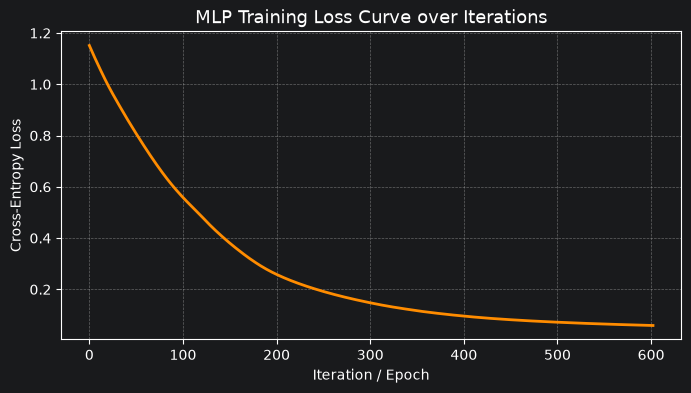

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(nn_model.loss_curve_, color="darkorange", lw=2)
plt.title("MLP Training Loss Curve over Iterations", fontsize=13)
plt.xlabel("Iteration / Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 10. Visualizing the Confusion Matrix

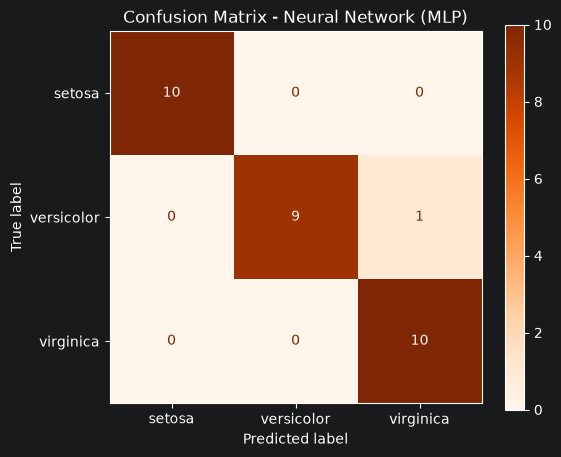

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=iris.target_names)
disp.plot(cmap=plt.cm.Oranges, ax=ax)
plt.title("Confusion Matrix - Neural Network (MLP)")
plt.grid(False)
plt.show()